# Exploración de estaciones y diseño de características para P3 — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P3 (agrupamiento de estaciones)
**Autor:** Joel Sánchez (PittJR1607) · **Rama:** `feature/p3-clustering`

**Propósito.** Responder con evidencia cuantitativa las preguntas de diseño previas al agrupamiento de P3 (*¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?*), usando la historia completa acordada por el equipo (diciembre de 2014 a septiembre de 2026, **39,078,984 viajes**).

**Preguntas que responde este notebook:**
1. **Cobertura y municipios de la red:** cuántas estaciones existen en la nomenclatura, cuántas quedan tras excluir las 14 dadas de baja (`ESTACIONES_EXCLUIDAS`), cómo se reparten entre Guadalajara (`GDL`), Zapopan (`ZPN`) y Tlaquepaque (`TLQ`), y qué estaciones tienen discrepancias entre viajes y nomenclatura.
2. **Viajes con mismo origen y destino (`Origen_Id == Destino_Id`) y duraciones extremas:** cuántos viajes duran menos de 60 s y cuántos salen y regresan a la misma estación; si los viajes `Origen_Id == Destino_Id` de $\ge 60$ s son errores de captura/devoluciones por falla mecánica o paseos recreativos reales (p. ej. Vía RecreActiva dominical), y cómo tratarlos sin distorsionar los grupos.
3. **Impacto de las estaciones incorporadas en los últimos años (expansión 2023–2026):** cómo perturba la diferencia de antigüedad (estaciones fundadoras de 142 meses contra las **98 estaciones con viajes abiertas entre mayo y agosto de 2026** con $\le 6$ meses) al volumen de viajes por estación, y cómo se corrige mediante tasas por mes activo y por anclaje.
4. **Firmas de comportamiento (horaria, semanal, rol en la red y evolución):** qué variables discriminan estaciones residenciales (emisoras matutinas), laborales/comerciales (atractoras vespertinas), centrales de alta rotación y periféricas recreativas, y por qué la latitud y longitud deben reservarse para localizar los grupos en el mapa y no para formarlos.

**Datos personales.** Solo se leen `Viaje_Id`, `Inicio_del_viaje`, `Fin_del_viaje`, `Origen_Id` y `Destino_Id` (`COLUMNAS_VIAJES` en `config.py`); nunca se cargan `Usuario_Id`, `Genero` ni `Año_de_nacimiento`.

In [1]:
# Objetivo: preparar el entorno del notebook y cargar rutas y constantes desde config.py.
# Resultado esperado: confirmación de que existen la nomenclatura y el Parquet consolidado de viajes.

%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from equipo52_module.config import (
    DURACION_MINIMA_SEGUNDOS,
    ESTACIONES_EXCLUIDAS,
    FECHA_FIN,
    FECHA_INICIO,
    NOMENCLATURA_FILE,
    VIAJES_FILE,
)
from equipo52_module.features import (
    SEGUNDOS_REDONDO_CORTO,
    construir_matriz_p3,
    quitar_viajes_cortos,
    quitar_viajes_redondos_cortos,
)

pd.set_option("display.max_columns", 60)
print(f"Periodo de análisis: {FECHA_INICIO} a {FECHA_FIN}")
print(f"Nomenclatura: {NOMENCLATURA_FILE.name} (existe: {NOMENCLATURA_FILE.exists()})")
print(f"Viajes Parquet: {VIAJES_FILE.name} (existe: {VIAJES_FILE.exists()})")

2026-10-18 05:46:28.598 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: /Users/pittjr/JSO_DEV/ITESM/MAESTRIA_IA/3rdTrim/TC5061-Proyecto-Equipo52


Periodo de análisis: 2014-12-01 a 2026-09-30
Nomenclatura: nomenclatura_2026_09.csv (existe: True)
Viajes Parquet: viajes.parquet (existe: True)


## 1. Cobertura de estaciones y distribución territorial en el AMG

Antes de agregar viajes por estación revisamos la nomenclatura oficial (`nomenclatura_2026_09.csv`), extraemos el municipio del prefijo del nombre (`GDL`, `ZPN`, `TLQ`) y cuantificamos las estaciones utilizables tras retirar las 14 estaciones dadas de baja (`ESTACIONES_EXCLUIDAS`, prefijo `ex-`, cuatro de ellas con capacidad 0).

In [2]:
# Objetivo: cuantificar las estaciones de la nomenclatura, su capacidad y su distribución por municipio.
# Resultado esperado: conteo total (484), excluidas (14), utilizables (470) y resumen estadístico por municipio.

nomenclatura = pd.read_csv(NOMENCLATURA_FILE).rename(
    columns={"id": "estacion_id", "dpcapacity": "capacidad",
             "latitude": "latitud", "longitude": "longitud"}
)
nomenclatura["municipio"] = nomenclatura["name"].str.extract(r"\(([A-Z]+)-\d+\)")[0].fillna("OTRO")

estaciones = nomenclatura[
    ~nomenclatura["estacion_id"].isin(ESTACIONES_EXCLUIDAS) & (nomenclatura["capacidad"] > 0)
].copy()

print(f"Estaciones totales en nomenclatura: {len(nomenclatura)}")
print(f"Estaciones excluidas (dadas de baja, prefijo ex-): {len(ESTACIONES_EXCLUIDAS)}")
print(f"Estaciones utilizables con capacidad > 0: {len(estaciones)}")
print(f"Total de anclajes instalados en estaciones utilizables: {estaciones["capacidad"].sum():,}\n")

resumen_mun = estaciones.groupby("municipio").agg(
    estaciones=("estacion_id", "count"),
    porcentaje_red=("estacion_id", lambda s: round(len(s) / len(estaciones) * 100, 1)),
    anclajes_totales=("capacidad", "sum"),
    capacidad_media=("capacidad", "mean"),
    capacidad_mediana=("capacidad", "median"),
    capacidad_min=("capacidad", "min"),
    capacidad_max=("capacidad", "max"),
).round(1)
display(resumen_mun)

Estaciones totales en nomenclatura: 484
Estaciones excluidas (dadas de baja, prefijo ex-): 14
Estaciones utilizables con capacidad > 0: 470
Total de anclajes instalados en estaciones utilizables: 8,021



,estaciones,porcentaje_red,anclajes_totales,capacidad_media,capacidad_mediana,capacidad_min,capacidad_max
municipio,,,,,,,
GDL,353,75.1,6070,17.2,15.0,11,39
TLQ,15,3.2,229,15.3,15.0,15,19
ZPN,102,21.7,1722,16.9,15.0,11,31


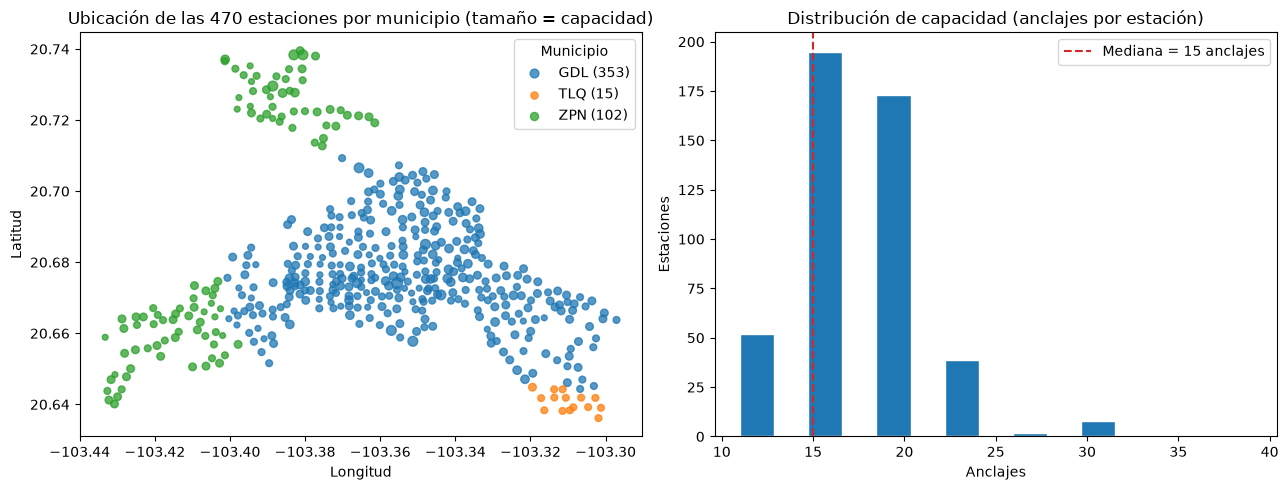

In [3]:
# Objetivo: visualizar la huella geográfica de las 470 estaciones utilizables por municipio y capacidad.
# Resultado esperado: mapa de Guadalajara, Zapopan y Tlaquepaque e histograma del número de anclajes.

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
colores_mun = {"GDL": "#1f77b4", "ZPN": "#2ca02c", "TLQ": "#ff7f0e"}
for mun, grupo in estaciones.groupby("municipio"):
    ax1.scatter(grupo["longitud"], grupo["latitud"], s=grupo["capacidad"] * 1.6,
                alpha=0.75, label=f"{mun} ({len(grupo)})", color=colores_mun.get(mun, "gray"))
ax1.set_title("Ubicación de las 470 estaciones por municipio (tamaño = capacidad)")
ax1.set_xlabel("Longitud")
ax1.set_ylabel("Latitud")
ax1.legend(title="Municipio")

ax2.hist(estaciones["capacidad"], bins=15, edgecolor="white", color="#1f77b4")
ax2.axvline(estaciones["capacidad"].median(), color="#d62728", ls="--",
            label=f"Mediana = {int(estaciones["capacidad"].median())} anclajes")
ax2.set_title("Distribución de capacidad (anclajes por estación)")
ax2.set_xlabel("Anclajes")
ax2.set_ylabel("Estaciones")
ax2.legend()
fig.tight_layout()

### Conclusiones de la nomenclatura y cobertura territorial

- De las **484 estaciones** registradas en septiembre de 2026, **14 están dadas de baja** (`ex-`, 4 de ellas con 0 anclajes) y quedan **470 estaciones utilizables** que suman **8,017 anclajes** en toda el Área Metropolitana de Guadalajara.
- La red está concentrada en **Guadalajara (`GDL`, 353 estaciones, 75.1 % de la red)** y **Zapopan (`ZPN`, 102 estaciones, 21.7 %)**, mientras que **Tlaquepaque (`TLQ`) cuenta con 15 estaciones (3.2 %)**.
- La capacidad mediana es de **15 anclajes** (media **17.1**, mínimo **11** y máximo **39**). Como una estación de 39 anclajes puede iniciar el triple de viajes que una de 11 con la misma ocupación por puerto, la matriz de P3 debe incluir la **intensidad por anclaje (`viajes_por_anclaje_mes`)** además del volumen mensual.

---

## 2. Auditoría de viajes: duraciones menores a 60 s y viajes con mismo origen y destino (`Origen_Id == Destino_Id`)

En equipo identificamos que existen viajes donde la estación de origen es igual a la de destino (`Origen_Id == Destino_Id`). Antes de decidir si deben eliminarse o conservarse para P3, medimos en los **39,078,984 viajes** cómo se cruza la condición `Origen_Id == Destino_Id` con la duración del viaje y con el día de la semana.

In [4]:
# Objetivo: auditar los 39,078,984 viajes cruzando validez de estación, duración (< 60 s vs >= 60 s)
# y viajes redondos (Origen_Id == Destino_Id).
# Resultado esperado: desglose exacto de cuántos viajes se descartan por cada regla y qué proporción
# de los viajes < 60 s corresponde a devoluciones inmediatas en la misma estación.

viajes_crudos = pd.read_parquet(VIAJES_FILE)
ids_validos = set(estaciones["estacion_id"])
estaciones_en_viajes = set(viajes_crudos["Origen_Id"].unique()) | set(viajes_crudos["Destino_Id"].unique())

sin_ficha = sorted(estaciones_en_viajes - set(nomenclatura["estacion_id"]))
sin_viajes = sorted(ids_validos - estaciones_en_viajes)

duracion_seg = (viajes_crudos["Fin_del_viaje"] - viajes_crudos["Inicio_del_viaje"]).dt.total_seconds()
mismo_od = viajes_crudos["Origen_Id"] == viajes_crudos["Destino_Id"]
en_red_valida = viajes_crudos["Origen_Id"].isin(ids_validos) & viajes_crudos["Destino_Id"].isin(ids_validos)
menor_60 = duracion_seg < DURACION_MINIMA_SEGUNDOS

print(f"Total de viajes en el Parquet (dic-2014 a sep-2026): {len(viajes_crudos):,}")
print(f"Estaciones con viajes pero sin ficha en nomenclatura: {sin_ficha}")
print(f"Estaciones utilizables en nomenclatura sin ningún viaje registrado: {sin_viajes}\n")

print(f"1) Viajes con estación excluida o sin ficha (14 ex- + {sin_ficha}): {(~en_red_valida).sum():,} ({(~en_red_valida).mean():.2%})")
print(f"2) Viajes con duración < {DURACION_MINIMA_SEGUNDOS} s: {menor_60.sum():,} ({menor_60.mean():.2%})")
print(f"   - De los < 60 s, mismo Origen = Destino: {(menor_60 & mismo_od).sum():,} ({(menor_60 & mismo_od).sum() / menor_60.sum():.2%} de los < 60 s)")
print(f"   - De los < 60 s, Origen != Destino: {(menor_60 & ~mismo_od).sum():,} ({(menor_60 & ~mismo_od).sum() / menor_60.sum():.2%} de los < 60 s)\n")

mascara_utiles = en_red_valida & (~menor_60)
viajes = viajes_crudos.loc[mascara_utiles].reset_index(drop=True)
del viajes_crudos

print(f"Viajes útiles para P3 (en las 469 estaciones activas y >= 60 s): {len(viajes):,} ({mascara_utiles.mean():.2%} del total)")

Total de viajes en el Parquet (dic-2014 a sep-2026): 39,078,984
Estaciones con viajes pero sin ficha en nomenclatura: [np.int64(124), np.int64(405), np.int64(407)]
Estaciones utilizables en nomenclatura sin ningún viaje registrado: [492]

1) Viajes con estación excluida o sin ficha (14 ex- + [np.int64(124), np.int64(405), np.int64(407)]): 162,847 (0.42%)
2) Viajes con duración < 60 s: 1,269,425 (3.25%)
   - De los < 60 s, mismo Origen = Destino: 1,205,688 (94.98% de los < 60 s)
   - De los < 60 s, Origen != Destino: 63,737 (5.02% de los < 60 s)



Viajes útiles para P3 (en las 469 estaciones activas y >= 60 s): 37,649,967 (96.34% del total)


In [5]:
# Objetivo: analizar los 1,516,002 viajes que tienen Origen_Id == Destino_Id DESPUÉS de quitar los < 60 s.
# Revisamos su distribución por tramos de duración y si ocurren más en fin de semana / domingo (Vía RecreActiva).
# Resultado esperado: tabla por tramo de duración y comparación entre viajes A -> B y viajes redondos A -> A.

dur_util_min = (viajes["Fin_del_viaje"] - viajes["Inicio_del_viaje"]).dt.total_seconds() / 60.0
es_redondo = viajes["Origen_Id"] == viajes["Destino_Id"]
dia_sem = viajes["Inicio_del_viaje"].dt.dayofweek

tramos = pd.cut(
    dur_util_min[es_redondo],
    bins=[1, 2, 3, 5, 15, 30, 60, 1e7],
    labels=[
        "1-2 min (devolución tras probar bici)",
        "2-3 min (vuelta a la manzana / falla)",
        "3-5 min (recorrido muy corto)",
        "5-15 min (mandado / paseo corto)",
        "15-30 min (paseo dentro de 30 min sin cargo)",
        "30-60 min (paseo extendido)",
        "> 60 min (uso prolongado / olvido)",
    ],
    right=False,
)
tabla_tramos = tramos.value_counts(sort=False).rename("viajes_redondos").to_frame()
tabla_tramos["porcentaje_%"] = (tabla_tramos["viajes_redondos"] / es_redondo.sum() * 100).round(2)
print(f"Total de viajes Origen = Destino con duración >= 60 s: {es_redondo.sum():,} ({es_redondo.mean():.2%} de los viajes útiles)\n")
display(tabla_tramos)

comparacion_od = pd.DataFrame({
    "Viajes entre estaciones distintas (A != B)": [
        int((~es_redondo).sum()),
        round(dur_util_min[~es_redondo].median(), 2),
        round((dia_sem[~es_redondo] >= 5).mean() * 100, 2),
        round((dia_sem[~es_redondo] == 6).mean() * 100, 2),
    ],
    "Viajes redondos >= 60 s (A == B)": [
        int(es_redondo.sum()),
        round(dur_util_min[es_redondo].median(), 2),
        round((dia_sem[es_redondo] >= 5).mean() * 100, 2),
        round((dia_sem[es_redondo] == 6).mean() * 100, 2),
    ],
}, index=["Número de viajes", "Duración mediana (min)", "% en fin de semana (sáb+dom)", "% en domingo (Vía RecreActiva)"])
display(comparacion_od)

Total de viajes Origen = Destino con duración >= 60 s: 1,516,002 (4.03% de los viajes útiles)



,viajes_redondos,porcentaje_%
1-2 min (devolución tras probar bici),146428,9.66
2-3 min (vuelta a la manzana / falla),49579,3.27
3-5 min (recorrido muy corto),85343,5.63
5-15 min (mandado / paseo corto),658385,43.43
15-30 min (paseo dentro de 30 min sin cargo),492696,32.50
30-60 min (paseo extendido),71977,4.75
> 60 min (uso prolongado / olvido),11594,0.76


,Viajes entre estaciones distintas (A != B),Viajes redondos >= 60 s (A == B)
Número de viajes,36133965.00,1516002.00
Duración mediana (min),9.62,12.05
% en fin de semana (sáb+dom),19.36,25.19
% en domingo (Vía RecreActiva),8.73,12.12


Resumen de prop_viajes_redondos en las 469 estaciones activas:
count    469.0000
mean       0.0459
std        0.0252
min        0.0085
10%        0.0234
25%        0.0298
50%        0.0407
75%        0.0535
90%        0.0729
95%        0.0960
max        0.2140

Top 10 estaciones con mayor proporción de viajes redondos:


,name,municipio,prop_viajes_redondos,fin_de_semana,duracion_mediana_min,salidas_por_mes,meses_activa
estacion_id,,,,,,,
353,(GDL-263)C. Aldama / C. 5 de Mayo,GDL,0.214,0.228,11.492,218.686,35
514,(ZPN-101) C. Volcán Quinceo/C. Ignacio C.,ZPN,0.184,0.309,11.850,76.000,2
464,(GDL-334) Rivas Guillén/Ortiz de Domínguez,GDL,0.172,0.218,12.267,191.500,4
61,(GDL-059) C. Miguel Blanco / C. Penitenciaria,GDL,0.161,0.206,8.867,1049.894,142
519,(ZPN-107) C. Colina Aria / Av. Díaz de León,ZPN,0.149,0.285,11.333,140.500,2
101,(ZPN-011) C. Pino Suárez / C. López Cotilla,ZPN,0.139,0.182,6.833,102.781,137
496,(GDL-331) J. Ortiz de Dmgz /Sebastián Allende,GDL,0.132,0.287,9.800,178.500,4
360,(GDL-255) C. Cabañas / C. Industria,GDL,0.129,0.224,10.800,173.600,35
37,(GDL-035) C. Mezquitán / Av. Hidalgo,GDL,0.128,0.184,9.367,982.141,142


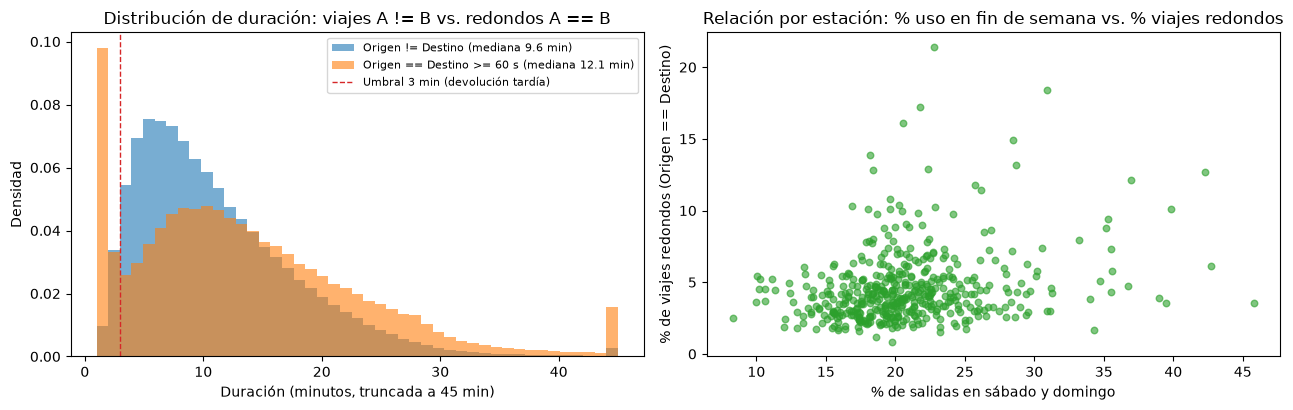

In [6]:
# Objetivo: identificar qué estaciones tienen mayor proporción de viajes redondos (>= 60 s).
# Resultado esperado: top 10 estaciones con mayor proporción de viajes redondos y gráfica comparativa de duración.

matriz_exploratoria = construir_matriz_p3(viajes, estaciones.set_index("estacion_id"), pd.Timestamp(FECHA_FIN))
matriz_exploratoria["fin_de_semana"] = matriz_exploratoria["d5"] + matriz_exploratoria["d6"]

top_redondos = (
    matriz_exploratoria.join(estaciones.set_index("estacion_id")[["name", "municipio"]])
    [["name", "municipio", "prop_viajes_redondos", "fin_de_semana", "duracion_mediana_min", "salidas_por_mes", "meses_activa"]]
    .sort_values("prop_viajes_redondos", ascending=False)
)
print("Resumen de prop_viajes_redondos en las 469 estaciones activas:")
print(matriz_exploratoria["prop_viajes_redondos"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).round(4).to_string())
print("\nTop 10 estaciones con mayor proporción de viajes redondos:")
display(top_redondos.head(10).round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.hist(dur_util_min[~es_redondo].clip(upper=45), bins=45, density=True, alpha=0.6, label="Origen != Destino (mediana 9.6 min)")
ax1.hist(dur_util_min[es_redondo].clip(upper=45), bins=45, density=True, alpha=0.6, label="Origen == Destino >= 60 s (mediana 12.1 min)")
ax1.axvline(3, color="#d62728", ls="--", lw=1, label="Umbral 3 min (devolución tardía)")
ax1.set_title("Distribución de duración: viajes A != B vs. redondos A == B")
ax1.set_xlabel("Duración (minutos, truncada a 45 min)")
ax1.set_ylabel("Densidad")
ax1.legend(fontsize=8)

ax2.scatter(matriz_exploratoria["fin_de_semana"] * 100, matriz_exploratoria["prop_viajes_redondos"] * 100,
            alpha=0.6, s=22, color="#2ca02c")
ax2.set_title("Relación por estación: % uso en fin de semana vs. % viajes redondos")
ax2.set_xlabel("% de salidas en sábado y domingo")
ax2.set_ylabel("% de viajes redondos (Origen == Destino)")
fig.tight_layout()

### Conclusiones y decisión sobre los viajes `Origen_Id == Destino_Id`

1. **Los falsos inicios ya están resueltos por la regla de 60 segundos:** en el Parquet hay **1,269,425 viajes `< 60 s` (3.25 %)** y el **94.98 % de ellos (1,205,688)** tienen `Origen_Id == Destino_Id`. Son usuarios que sacan una bicicleta y la devuelven al mismo anclaje en segundos porque detectan una falla mecánica. Al aplicar `quitar_viajes_cortos(viajes, 60)` desaparece ese ruido.
2. **Los 1,516,002 viajes con `Origen_Id == Destino_Id` que duran $\ge 60$ s (4.03 % de los viajes útiles) son en su mayoría paseos reales, no errores:**
   - El **75.93 % dura entre 5 y 30 minutos** (658,385 viajes de 5–15 min y 492,696 de 15–30 min, justo dentro de los 30 minutos incluidos sin cobro adicional en MiBici), con una duración mediana de **12.10 min** (26 % más largos que los **9.60 min** de los viajes entre estaciones distintas).
   - Ocurren mucho más en **sábado y domingo (25.19 % contra 19.36 %)** y en **domingo de Vía RecreActiva (12.12 % contra 8.73 %)**.
   - Solo un **14.37 % (217,916 viajes)** dura entre **1 y 3 minutos** (devoluciones tardías tras probar la bicicleta una cuadra).
3. **Decisión para P3:**
   - **No deben eliminarse todos los viajes `Origen_Id == Destino_Id` $\ge 60$ s**, porque su frecuencia por estación (`prop_viajes_redondos`, mediana 4.07 %, percentil 95 de 9.60 % y máximo de 21.40 %) es una señal genuina que distingue a las estaciones recreativas y barriales de las estaciones puramente conmutadoras.
   - Además, agregamos en `features.py` la función `quitar_viajes_redondos_cortos(viajes, segundos_maximos=180)` y la opción `--sin-redondos-cortos` en `train_p3.py` para comprobar en el notebook `3.1` que retirar los viajes redondos de 1 a 3 minutos deja el agrupamiento prácticamente intacto (**ARI = 1.000 en $k = 2$** y **ARI = 0.924 en $k = 4$**).

---

## 3. Estaciones incorporadas en los últimos años y cómo evitar que perturben el agrupamiento

La segunda recomendación del equipo señala que MiBici incorporó estaciones nuevas en los últimos años —en especial la expansión de **mayo a agosto de 2026**— que por llevar pocos meses operando tienen muchos menos viajes acumulados y podrían sesgar la matriz de estaciones. Aquí medimos exactamente cuántas estaciones hay por cohorte de antigüedad y cómo cambia el volumen antes y después de normalizar por meses activos.

In [7]:
# Objetivo: cuantificar las cohortes de antigüedad de las 469 estaciones activas y medir la correlación
# entre antigüedad y volumen antes y después de normalizar por meses activos.
# Resultado esperado: tabla comparativa de las 4 cohortes (Nuevas 2026, Recientes, Intermedias y Fundadoras)
# y coeficientes de correlación r de Pearson.

salidas_acumuladas = viajes.groupby("Origen_Id").size().reindex(matriz_exploratoria.index, fill_value=0)
tabla_edad = matriz_exploratoria[[
    "meses_activa", "salidas_por_mes", "viajes_por_anclaje_mes",
    "share_viajes_ultimos_12m", "crecimiento_vs_esperado", "fin_de_semana", "prop_viajes_redondos"
]].copy()
tabla_edad["salidas_acumuladas"] = salidas_acumuladas
tabla_edad["cohorte"] = pd.cut(
    tabla_edad["meses_activa"],
    bins=[0, 6, 36, 96, 200],
    labels=[
        "Nuevas 2026 (<= 6 meses)",
        "Recientes (7 a 36 meses)",
        "Intermedias (37 a 96 meses)",
        "Fundadoras (> 96 meses)",
    ],
)

resumen_cohortes = tabla_edad.groupby("cohorte", observed=False).agg(
    estaciones=("meses_activa", "count"),
    meses_mediana=("meses_activa", "median"),
    salidas_acumuladas_mediana=("salidas_acumuladas", "median"),
    salidas_por_mes_mediana=("salidas_por_mes", "median"),
    viajes_anclaje_mes_mediana=("viajes_por_anclaje_mes", "median"),
    share_ultimos_12m_mediana=("share_viajes_ultimos_12m", "median"),
    fin_semana_mediana=("fin_de_semana", "median"),
    redondos_mediana=("prop_viajes_redondos", "median"),
).round(3)
display(resumen_cohortes)

r_crudo = tabla_edad["meses_activa"].corr(tabla_edad["salidas_acumuladas"])
r_norm = tabla_edad["meses_activa"].corr(tabla_edad["salidas_por_mes"])
print(f"Correlación meses_activa vs. salidas_acumuladas (sin normalizar): r = {r_crudo:.3f}")
print(f"Correlación meses_activa vs. salidas_por_mes (normalizado):       r = {r_norm:.3f}")

,estaciones,meses_mediana,salidas_acumuladas_mediana,salidas_por_mes_mediana,viajes_anclaje_mes_mediana,share_ultimos_12m_mediana,fin_semana_mediana,redondos_mediana
cohorte,,,,,,,,
Nuevas 2026 (<= 6 meses),98,4.0,637.0,188.125,21.842,1.000,0.248,0.043
Recientes (7 a 36 meses),73,35.0,11947.0,367.107,46.404,0.367,0.219,0.041
Intermedias (37 a 96 meses),65,95.0,50697.0,595.895,76.436,0.146,0.195,0.041
Fundadoras (> 96 meses),233,122.0,115421.0,880.021,113.248,0.098,0.191,0.038


Correlación meses_activa vs. salidas_acumuladas (sin normalizar): r = 0.621
Correlación meses_activa vs. salidas_por_mes (normalizado):       r = 0.483


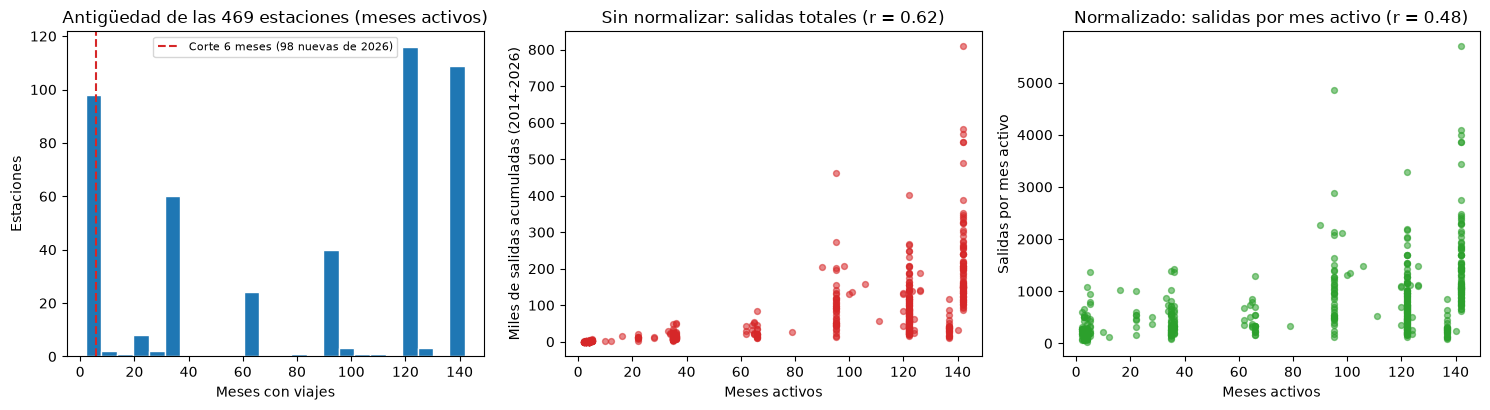

In [8]:
# Objetivo: visualizar cómo las estaciones nuevas de 2026 quedan aplastadas cerca de cero en conteo acumulado,
# pero muestran su ritmo real de operación al dividir entre sus meses activos.
# Resultado esperado: histograma de antigüedad y comparación de salidas acumuladas vs. salidas por mes activo.

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.2))
ax1.hist(tabla_edad["meses_activa"], bins=24, edgecolor="white", color="#1f77b4")
ax1.axvline(6, color="#d62728", ls="--", label="Corte 6 meses (98 nuevas de 2026)")
ax1.set_title("Antigüedad de las 469 estaciones (meses activos)")
ax1.set_xlabel("Meses con viajes")
ax1.set_ylabel("Estaciones")
ax1.legend(fontsize=8)

ax2.scatter(tabla_edad["meses_activa"], tabla_edad["salidas_acumuladas"] / 1000, alpha=0.55, s=18, color="#d62728")
ax2.set_title(f"Sin normalizar: salidas totales (r = {r_crudo:.2f})")
ax2.set_xlabel("Meses activos")
ax2.set_ylabel("Miles de salidas acumuladas (2014-2026)")

ax3.scatter(tabla_edad["meses_activa"], tabla_edad["salidas_por_mes"], alpha=0.55, s=18, color="#2ca02c")
ax3.set_title(f"Normalizado: salidas por mes activo (r = {r_norm:.2f})")
ax3.set_xlabel("Meses activos")
ax3.set_ylabel("Salidas por mes activo")
fig.tight_layout()

### Conclusiones sobre las estaciones nuevas y su efecto en P3

1. **Cuatro etapas claras de expansión en las 469 estaciones activas** (la estación 492 aún no registra ningún viaje y queda fuera porque no tiene patrón que describir):
   - **Fundadoras ($> 96$ meses, 233 estaciones, 49.7 % de la red):** mediana de **122 meses**, **115,421 salidas acumuladas** y **880.0 salidas/mes** (**113.2 viajes/anclaje-mes**).
   - **Intermedias (37 a 96 meses, 65 estaciones, 13.9 %):** mediana de **95 meses**, **50,697 salidas acumuladas** y **595.9 salidas/mes**.
   - **Recientes (7 a 36 meses, 73 estaciones, 15.6 %):** mediana de **35 meses**, **11,947 salidas acumuladas** y **367.1 salidas/mes**.
   - **Nuevas de 2026 ($\le 6$ meses, 98 estaciones abiertas entre mayo y agosto de 2026, 20.9 %):** mediana de **4 meses**, apenas **637 salidas acumuladas** (181 veces menos que una fundadora), pero ya operan a un ritmo mediano de **188.1 salidas/mes** (**21.8 viajes/anclaje-mes**), con mayor uso en fin de semana (**24.8 %** contra **19.1 %** en fundadoras).
2. **Cómo evitamos que perturben el agrupamiento:**
   - **En `features.py`:** ningún conteo crudo entra a la matriz. Todos los volúmenes se dividen entre `meses_activa` (`salidas_por_mes`, `llegadas_por_mes`, `viajes_por_anclaje_mes`, `flujo_neto_por_mes`) —lo que reduce la correlación con la antigüedad de **r = 0.621 a r = 0.483**— y las firmas horaria (`h00..h23`) y semanal (`d0..d6`) se expresan como proporciones que suman 1 en cada estación.
   - **En `train_p3.py` y el notebook `3.1`:** además del modelo sobre las 469 estaciones, implementamos la opción `--solo-consolidadas`, que ajusta el `StandardScaler` y los centroides de K-Means **únicamente con las 371 estaciones consolidadas ($> 6$ meses)** y luego clasifica por distancia al centroide más cercano a las **98 estaciones nuevas de 2026**, verificando que no distorsionen los grupos (en $k = 4$, la silueta sobre las 371 consolidadas sube de **0.105 a 0.127** y el índice Davies-Bouldin mejora de **2.309 a 2.102**).

---

## 4. Firmas horarias, semanales y rol en la red (fuentes vs. sumideros)

Verificamos ahora que las proporciones horarias, semanales y de balance realmente separen estaciones con vocaciones urbanas distintas dentro de la ciudad.

,salidas_por_mes,llegadas_por_mes,viajes_por_anclaje_mes,flujo_neto_por_mes,balance,num_destinos,duracion_mediana_min,fin_de_semana
count,469.000,469.000,469.000,469.000,469.000,469.000,469.000,469.000
mean,747.060,752.905,87.665,5.845,-0.018,257.821,10.124,0.209
std,722.269,772.291,76.922,178.184,0.108,98.814,2.086,0.052
min,31.000,30.500,4.100,-1395.336,-0.320,27.000,4.033,0.083
10%,156.983,127.047,17.146,-129.425,-0.144,97.000,7.723,0.155
25%,239.000,220.811,28.239,-70.459,-0.088,181.000,8.817,0.178
50%,529.286,534.533,61.671,-17.000,-0.022,282.000,9.883,0.201
75%,1026.116,1015.120,127.873,53.400,0.040,340.000,11.500,0.229
90%,1536.408,1567.245,187.832,171.497,0.111,365.200,12.943,0.269
max,5700.648,7392.225,549.256,1691.577,0.435,428.000,16.150,0.458


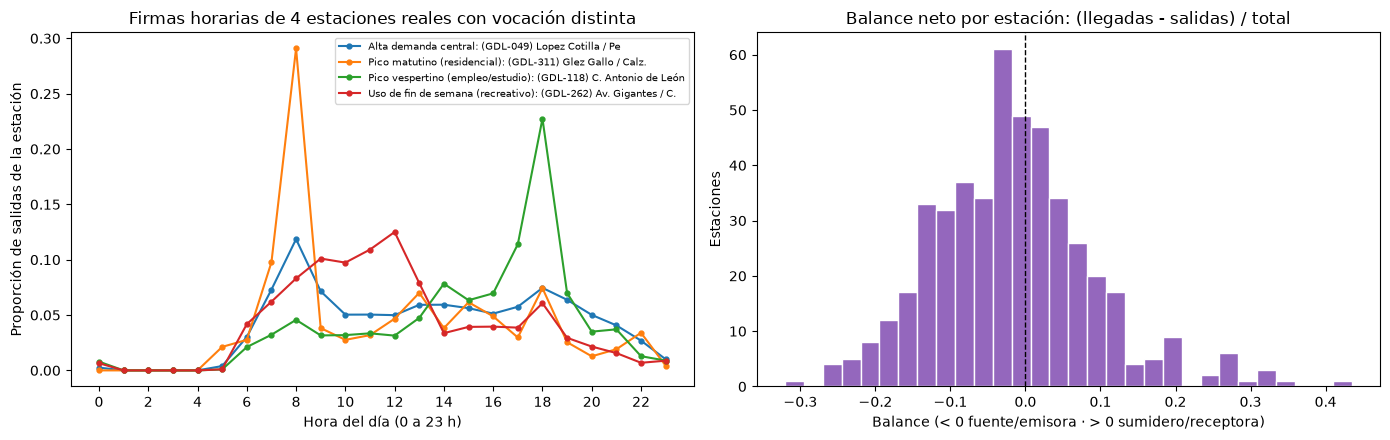

In [9]:
# Objetivo: contrastar las firmas horarias de estaciones reales con perfiles distintos (emisor matutino,
# atractor vespertino, alta rotación central y recreativo de fin de semana) y cuantificar el rol en la red.
# Resultado esperado: gráfica de perfiles horarios contrastantes y estadísticos de balance y destinos.

horas_cols = [f"h{h:02d}" for h in range(24)]
con_nombres = matriz_exploratoria.join(estaciones.set_index("estacion_id")[["name", "municipio"]])

id_central = con_nombres["salidas_por_mes"].idxmax()
id_matutina = (con_nombres["h07"] + con_nombres["h08"]).idxmax()
id_vespertina = (con_nombres["h17"] + con_nombres["h18"] + con_nombres["h19"]).idxmax()
id_recreativa = con_nombres[con_nombres["meses_activa"] > 12]["fin_de_semana"].idxmax()

ejemplos = [
    (id_central, "Alta demanda central"),
    (id_matutina, "Pico matutino (residencial)"),
    (id_vespertina, "Pico vespertino (empleo/estudio)"),
    (id_recreativa, "Uso de fin de semana (recreativo)"),
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for est_id, etiqueta in ejemplos:
    fila = con_nombres.loc[est_id]
    ax1.plot(range(24), fila[horas_cols].to_numpy(), marker="o", ms=3.5,
             label=f"{etiqueta}: {fila["name"][:28]}")
ax1.set_title("Firmas horarias de 4 estaciones reales con vocación distinta")
ax1.set_xlabel("Hora del día (0 a 23 h)")
ax1.set_ylabel("Proporción de salidas de la estación")
ax1.set_xticks(range(0, 24, 2))
ax1.legend(fontsize=7.5)

ax2.hist(con_nombres["balance"], bins=30, edgecolor="white", color="#9467bd")
ax2.axvline(0, color="black", ls="--", lw=1)
ax2.set_title("Balance neto por estación: (llegadas - salidas) / total")
ax2.set_xlabel("Balance (< 0 fuente/emisora · > 0 sumidero/receptora)")
ax2.set_ylabel("Estaciones")
fig.tight_layout()

resumen_rol = con_nombres[[
    "salidas_por_mes", "llegadas_por_mes", "viajes_por_anclaje_mes",
    "flujo_neto_por_mes", "balance", "num_destinos", "duracion_mediana_min", "fin_de_semana"
]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3)
display(resumen_rol)

## 5. Matriz final estación × característica (`construir_matriz_p3`) y relación con la geografía

Cerramos la exploración validando la matriz que genera `construir_matriz_p3` en `equipo52_module/features.py`: dimensiones exactas, ausencia de valores faltantes y correlación con latitud/longitud.

In [10]:
# Objetivo: inspeccionar la matriz completa de P3 (469 estaciones x 42 características de uso + lat/lon)
# y medir cuánto se correlacionan las variables de uso con las coordenadas geográficas.
# Resultado esperado: 0 valores nulos, resumen por grupo de variables y correlaciones máximas con latitud/longitud.

columnas_uso = [c for c in matriz_exploratoria.columns if c not in ("latitud", "longitud", "fin_de_semana")]
print(f"Estaciones en la matriz: {matriz_exploratoria.shape[0]}")
print(f"Características de uso:  {len(columnas_uso)}")
print(f"Valores faltantes (NaN): {int(matriz_exploratoria[columnas_uso].isna().sum().sum())}\n")

corr_lat = matriz_exploratoria[columnas_uso].apply(lambda s: s.corr(matriz_exploratoria["latitud"])).abs().max()
corr_lon = matriz_exploratoria[columnas_uso].apply(lambda s: s.corr(matriz_exploratoria["longitud"])).abs().max()
print(f"Correlación absoluta máxima con latitud:  |r| = {corr_lat:.3f}")
print(f"Correlación absoluta máxima con longitud: |r| = {corr_lon:.3f}")

grupos_tabla = pd.DataFrame([
    ("A. Nivel de actividad (3)", "salidas_por_mes, llegadas_por_mes, viajes_por_anclaje_mes", "Separa núcleo de alta rotación de periferia de baja intensidad"),
    ("B. Firma horaria (24)", "h00 .. h23 (proporción de salidas por hora)", "Distingue emisoras matutinas (7-9 h) de atractoras vespertinas (17-19 h)"),
    ("C. Firma semanal (7)", "d0 .. d6 (lunes a domingo)", "Separa estaciones laborales (lun-vie) de recreativas (sáb-dom)"),
    ("D. Rol en la red (3)", "flujo_neto_por_mes, balance, num_destinos", "Identifica estaciones fuente (-), sumidero (+) y grado de conectividad"),
    ("E. Tipo de viaje (2)", "prop_viajes_redondos, duracion_mediana_min", "Captura paseos circulares y duración típica sin distorsión por extremos"),
    ("F. Evolución histórica (3)", "meses_activa, share_viajes_ultimos_12m, crecimiento_vs_esperado", "Separa estaciones fundadoras consolidadas de expansiones recientes"),
], columns=["Bloque (n vars)", "Variables en features.py", "Justificación operativa para P3"])
display(grupos_tabla)

Estaciones en la matriz: 469
Características de uso:  42
Valores faltantes (NaN): 0

Correlación absoluta máxima con latitud:  |r| = 0.327
Correlación absoluta máxima con longitud: |r| = 0.504


,Bloque (n vars),Variables en features.py,Justificación operativa para P3
0,A. Nivel de actividad (3),"salidas_por_mes, llegadas_por_mes, viajes_por_...",Separa núcleo de alta rotación de periferia de...
1,B. Firma horaria (24),h00 .. h23 (proporción de salidas por hora),Distingue emisoras matutinas (7-9 h) de atract...
2,C. Firma semanal (7),d0 .. d6 (lunes a domingo),Separa estaciones laborales (lun-vie) de recre...
3,D. Rol en la red (3),"flujo_neto_por_mes, balance, num_destinos","Identifica estaciones fuente (-), sumidero (+)..."
4,E. Tipo de viaje (2),"prop_viajes_redondos, duracion_mediana_min",Captura paseos circulares y duración típica si...
5,F. Evolución histórica (3),"meses_activa, share_viajes_ultimos_12m, crecim...",Separa estaciones fundadoras consolidadas de e...


### Conclusiones generales para el modelado de P3 (`train_p3.py` y notebook `3.1`)

1. **Tamaño real del problema:** de 484 estaciones en la nomenclatura se excluyen las **14 dadas de baja** y la estación **492** (sin viajes aún), obteniendo una matriz limpia de **469 estaciones activas × 42 características de uso** calculadas sobre **37,649,967 viajes útiles** ($\ge 60$ s).
2. **Tratamiento de viajes `Origen_Id == Destino_Id`:** el filtro `< 60 s` elimina **1,205,688 devoluciones inmediatas** (94.98 % de los viajes menores a un minuto). Los **1,516,002 viajes redondos $\ge 60$ s** se conservan porque el **75.93 % dura entre 5 y 30 min** y se concentra en domingo (**12.12 % vs. 8.73 %**), alimentando la característica `prop_viajes_redondos`; adicionalmente se probará la sensibilidad al descartar el tramo de 1 a 3 min (`quitar_viajes_redondos_cortos`).
3. **Control del efecto de las estaciones nuevas (98 abiertas en 2026):** normalizar por `meses_activa` reduce la correlación con la antigüedad de **r = 0.621 a r = 0.483**, y en el modelado se evaluará también el ajuste exclusivo sobre las **371 estaciones consolidadas ($> 6$ meses)** con proyección posterior de las 98 nuevas (`--solo-consolidadas`).
4. **Geografía fuera del entrenamiento, dentro de la interpretación:** las coordenadas tienen correlación moderada-baja con el uso ($|r| \le 0.40$ con latitud y $|r| \le 0.48$ con longitud); por eso `latitud` y `longitud` se usan únicamente en la **línea base geográfica (`geo`, $k=5$)** y para mapear dónde se ubican los grupos resultantes en Guadalajara, Zapopan y Tlaquepaque.